In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd
import numpy as np

In [8]:
def plot_spectra(df_UV_Vis=None, palette='viridis',
                 xmin=0, xmax=0, ymin=0, ymax=0):

    if df_UV_Vis is None:
        return

    df_UV_Vis = df_UV_Vis.apply(pd.to_numeric, errors='coerce')
    cols = df_UV_Vis.columns[1:]

    # Parse times from column headers
    times = np.array([float(c) for c in cols])

    cmap = plt.get_cmap(palette)
    norm = mcolors.Normalize(vmin=times.min(), vmax=times.max())

    fig, ax = plt.subplots(figsize=(8, 6))

    for col, t in zip(cols, times):
        ax.plot(df_UV_Vis.iloc[:, 0], df_UV_Vis[col], color=cmap(norm(t)))

    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    plt.colorbar(sm, ax=ax, label='irradiation time / s')

    ax.set_xlabel('wavelength / nm')
    ax.set_ylabel('absorbance')
    if xmin != 0: ax.set_xlim(left=xmin)
    if xmax != 0: ax.set_xlim(right=xmax)
    if ymin != 0: ax.set_ylim(bottom=ymin)
    if ymax != 0: ax.set_ylim(top=ymax)

    plt.tight_layout()
    plt.show()

In [9]:
def plot_spectra_grid(df_UV_Vis=None, palette='viridis',
                      xmin=0, xmax=0, ymin=0, ymax=0,
                      ncols=4):

    if df_UV_Vis is None:
        return

    df_UV_Vis = df_UV_Vis.apply(pd.to_numeric, errors='coerce')
    cols  = df_UV_Vis.columns[1:]
    times = np.array([float(c) for c in cols])
    n     = len(cols)

    cmap = plt.get_cmap(palette)
    norm = mcolors.Normalize(vmin=times.min(), vmax=times.max())

    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(ncols * 3, nrows * 2.5),
                             sharex=True, sharey=True)
    axes = np.array(axes).reshape(-1)

    for i, (col, t) in enumerate(zip(cols, times)):
        ax = axes[i]
        ax.plot(df_UV_Vis.iloc[:, 0], df_UV_Vis[col], color=cmap(norm(t)), lw=0.8)
        ax.set_title(f't = {t:.0f} s', fontsize=8)
        ax.tick_params(labelsize=7)

        if xmin != 0: ax.set_xlim(left=xmin)
        if xmax != 0: ax.set_xlim(right=xmax)
        if ymin != 0: ax.set_ylim(bottom=ymin)
        if ymax != 0: ax.set_ylim(top=ymax)

    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    fig.supxlabel('wavelength / nm', fontsize=10)
    fig.supylabel('absorbance', fontsize=10)

    plt.tight_layout()
    plt.show()

In [10]:
file = r"E:\02_Analyzed\04_Students\06_Jonas\01_UV_Vis\QY_test\260423_NST19_dioxane_19uM_305nm_no_filter_kinetics.csv"
df = pd.read_csv(file)

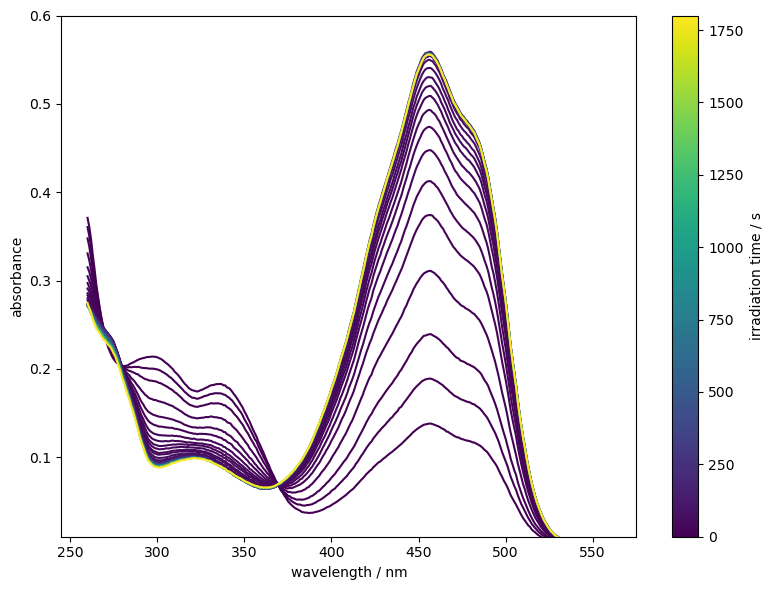

In [11]:
plot_spectra(df,
             ymin=0.01,
             ymax=0.6)

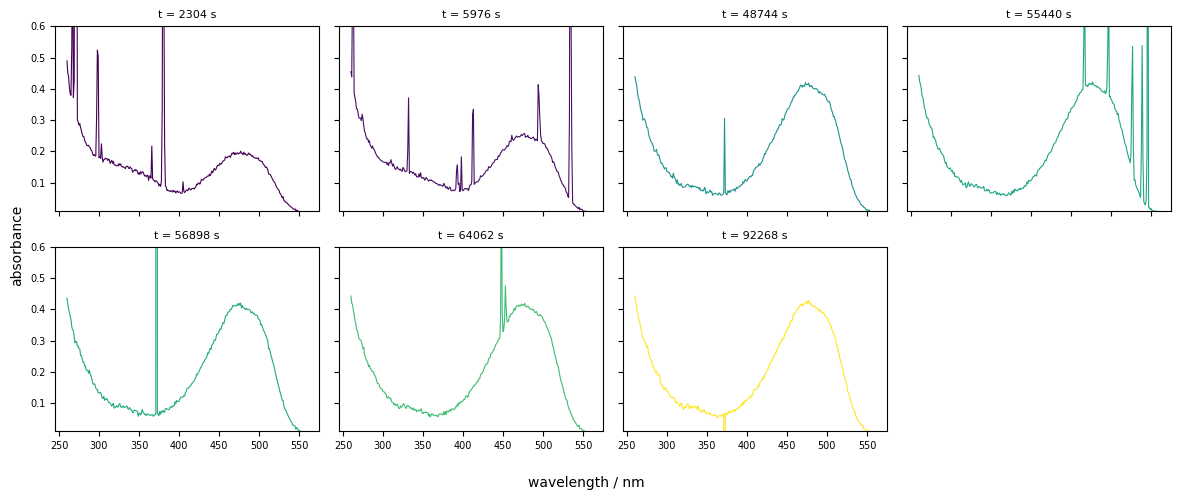

In [12]:
file_removed = r"E:\02_Analyzed\04_Students\06_Jonas\01_UV_Vis\260414_NST20_MeOH\365nm\kinetics_df_removed_spectra.csv"
df_removed = pd.read_csv(file_removed)

plot_spectra_grid(df_removed,
                  ymin=0.01,
                  ymax=0.6)